# TP Jour 4 — Tests d'Hypothèses Statistiques, Segmentation & Restitution BI

### Objectifs de la séance
1. Valider scientifiquement deux hypothèses métier sur votre dataset à l'aide de **tests statistiques adaptés** (`scipy.stats`).
2. Construire une **segmentation / typologie non supervisée (K-Means)** combinant agrégation distribuée **PySpark**, transformation d'asymétrie (`log1p`), standardisation (`StandardScaler`) et labellisation métier vers **`/lakehouse/gold/`**.
3. Développer votre **Dashboard Streamlit interactif** dans `app/dashboard.py` (`http://localhost:8501`) en documentant chaque requête SQL et chaque choix statistique.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score
from sklearn.preprocessing import StandardScaler

from pyspark.ml import Pipeline
from pyspark.ml.clustering import KMeans as SparkKMeans
from pyspark.ml.evaluation import ClusteringEvaluator
from pyspark.ml.feature import StandardScaler as SparkStandardScaler
from pyspark.ml.feature import VectorAssembler
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

spark = (
    SparkSession.builder
    .appName("J4_Stats_Segmentation_Dashboard")
    .config("spark.ui.showConsoleProgress", "false")  # pas de barres de progression dans les sorties
    .getOrCreate()
)

# pandas 3 (imposé par l'image) : avertissement de compatibilité PySpark connu, sans effet sur nos
# conversions (petites tables numériques / texte, contrôlées par les assert)
warnings.filterwarnings("ignore", message="PySpark does not yet fully support pandas")

# Style graphique commun (figures légères : dpi modéré pour ne pas alourdir le notebook)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 80, "axes.titleweight": "bold"})

:: loading settings :: url = jar:file:/opt/venv/lib/python3.15/site-packages/pyspark/jars/ivy-2.5.3.jar!/org/apache/ivy/core/settings/ivysettings.xml
Ivy Default Cache set to: /root/.ivy2.5.2/cache
The jars for the packages stored in: /root/.ivy2.5.2/jars
io.delta#delta-spark_4.2_2.13 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-077a41c6-d39d-426d-8aa1-78aeae092469;1.0
	confs: [default]
	found io.delta#delta-spark_4.2_2.13;4.4.1 in central
	found io.delta#delta-storage;4.4.1 in central


	found io.unitycatalog#unitycatalog-client;0.6.0 in central
	found org.slf4j#slf4j-api;2.0.13 in central
	found org.apache.logging.log4j#log4j-slf4j2-impl;2.25.3 in central
	found org.apache.logging.log4j#log4j-api;2.25.3 in central
	found com.google.code.findbugs#jsr305;3.0.2 in central
	found io.unitycatalog#unitycatalog-hadoop;0.6.0 in central
	found org.apache.logging.log4j#log4j-core;2.25.3 in central


	found io.delta#delta-kernel-api;4.4.1 in central
	found org.roaringbitmap#RoaringBitmap;0.9.25 in central
	found com.fasterxml.jackson.core#jackson-databind;2.13.5 in central
	found com.fasterxml.jackson.core#jackson-annotations;2.13.5 in central
	found com.fasterxml.jackson.core#jackson-core;2.13.5 in central
	found com.fasterxml.jackson.datatype#jackson-datatype-jdk8;2.13.5 in central
	found org.roaringbitmap#shims;0.9.25 in central
	found io.delta#delta-kernel-defaults;4.4.1 in central
	found org.apache.hadoop#hadoop-client-runtime;3.4.2 in central
	found org.apache.parquet#parquet-hadoop;1.16.0 in central
	found org.apache.parquet#parquet-column;1.16.0 in central
	found org.apache.parquet#parquet-common;1.16.0 in central


	found org.apache.parquet#parquet-format-structures;1.16.0 in central
	found javax.annotation#javax.annotation-api;1.3.2 in central
	found org.apache.parquet#parquet-encoding;1.16.0 in central
	found org.locationtech.jts#jts-core;1.20.0 in central
	found org.xerial.snappy#snappy-java;1.1.10.7 in central
	found io.airlift#aircompressor;2.0.2 in central
	found commons-pool#commons-pool;1.6 in central
	found com.github.luben#zstd-jni;1.5.7-3 in central
	found org.apache.hadoop#hadoop-client-api;3.4.2 in central
	found commons-logging#commons-logging;1.3.0 in central
	found org.apache.parquet#parquet-jackson;1.16.0 in central
	found io.delta#delta-kernel-unitycatalog;4.4.1 in central
:: resolution report :: resolve 697ms :: artifacts dl 35ms
	:: modules in use:
	com.fasterxml.jackson.core#jackson-annotations;2.13.5 from central in [default]
	com.fasterxml.jackson.core#jackson-core;2.13.5 from central in [default]
	com.fasterxml.jackson.core#jackson-databind;2.13.5 from central in [default]

:: retrieving :: org.apache.spark#spark-submit-parent-077a41c6-d39d-426d-8aa1-78aeae092469
	confs: [default]
	0 artifacts copied, 33 already retrieved (0kB/11ms)


26/11/25 11:04:29 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
/opt/venv/lib/python3.15/site-packages/pyspark/testing/utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


## 1. Inférence Statistique : Tester vos Hypothèses Métier (`scipy.stats`)

Choisissez **au moins deux tests statistiques** pertinents pour votre sujet parmi :
- **Comparaison de 2 groupes indépendants** sur une variable asymétrique : **Mann-Whitney U** (`stats.mannwhitneyu`).
- **Comparaison de $k \ge 3$ groupes** : **Kruskal-Wallis** (`stats.kruskal`).
- **Lien monotone entre 2 variables quantitatives** non gaussiennes : **Corrélation de rangs de Spearman** (`stats.spearmanr`).
- **Dépendance entre 2 variables qualitatives** : **Test du $\chi^2$** (`stats.chi2_contingency`).

### Exercice 1.1 — Formuler $H_0 / H_1$, projeter les colonnes utiles depuis Silver et conclure
> **Bonne pratique Big Data :** Ne faites jamais `.toPandas()` sur toute une table Silver brute ! Filtrez et sélectionnez (`select(...)`) uniquement les colonnes nécessaires côté PySpark avant de rapatrier les données vers le driver.

**Formulation de nos hypothèses :**

*Échantillon des tests #1 et #2 : grain **jeu** (`app_id`), jeux ayant au moins 20 avis et un temps de jeu réellement mesuré (cf. §1.2), soit 3 438 jeux portant 94,5 % des avis. Seuil de risque α = 5 %.*

- **Test #1 (Spearman, piste « temps de jeu ») :** $H_0 =$ `pas de lien monotone entre le temps de jeu médian et le taux de recommandation d'un jeu (ρ = 0)` / $H_1 =$ `les deux variables sont liées de façon monotone (ρ ≠ 0)` *(Justification du choix du test : `deux variables quantitatives non gaussiennes (temps de jeu : skewness 29, quelques jeux à plus de 3 000 h ; taux de recommandation borné dans [0, 1] et asymétrique à gauche). La corrélation de rangs est robuste à ces extrêmes, contrairement à Pearson`)*
- **Test #2 (Kruskal-Wallis + post-hoc Mann-Whitney U) :** $H_0 =$ `le taux de recommandation a la même distribution dans les 5 gammes de prix` / $H_1 =$ `au moins une gamme de prix se distingue` *(Justification du choix du test : `k = 5 groupes indépendants, très déséquilibrés (54 à 1 539 jeux), variable non normale : c'est l'alternative non paramétrique à l'ANOVA. Le post-hoc de Mann-Whitney avec correction de Bonferroni (10 paires) localise les écarts`)*
- **Test #3 (χ² d'indépendance, piste « signaux des avis ») :** $H_0 =$ `le fait qu'un avis soit jugé utile (au moins 1 vote) est indépendant de son sens (positif / négatif)` / $H_1 =$ `utilité et sens de l'avis sont dépendants` *(Justification du choix du test : `deux variables qualitatives binaires sur les 3,76 M avis, avec des effectifs attendus très supérieurs à 5. La table 2x2 est agrégée côté Spark. Avec un n aussi grand, la p-value sera quasi nulle : on juge donc surtout la taille d'effet, le V de Cramér`)*

In [2]:
SILVER_MAIN_PATH = "/lakehouse/silver/steam_reviews_enriched"
MIN_REVIEWS = 20  # en dessous, le taux de recommandation d'un jeu est trop bruité (IC 95 % > ±20 points)
ALPHA = 0.05

silver = spark.read.format("delta").load(SILVER_MAIN_PATH)
SNAPSHOT_YEAR = silver.agg(F.max("release_year")).first()[0]  # année de collecte du catalogue

# Agrégation distribuée au grain JEU (3,76 M avis -> ~9 000 lignes). Les attributs du catalogue (prix, temps
# de jeu, propriétaires...) sont constants par jeu -> ANY_VALUE ; les signaux d'avis sont agrégés (moyennes
# de booléens = taux). Petite table réutilisée par toutes les sections -> cache.
games_sdf = (
    silver.groupBy("app_id")
    .agg(
        F.any_value("game_name").alias("game_name"),
        F.any_value("primary_genre").alias("primary_genre"),
        F.any_value("release_year").alias("release_year"),
        F.any_value("price").alias("price"),
        F.any_value("price_tier").alias("price_tier"),
        F.any_value("owners_mid").alias("owners_mid"),
        F.any_value("average_playtime").alias("average_playtime"),
        F.any_value("median_playtime").alias("median_playtime"),
        F.any_value("catalog_positive_ratio").alias("catalog_positive_ratio"),
        F.count("*").alias("n_reviews"),
        F.avg(F.col("is_recommended").cast("double")).alias("positive_ratio"),
        F.avg(F.col("is_helpful").cast("double")).alias("helpful_ratio"),
        F.avg(F.col("is_contrarian_review").cast("double")).alias("contrarian_ratio"),
    )
    .withColumn("game_age", F.lit(SNAPSHOT_YEAR) - F.col("release_year"))
    .withColumn("playtime_measured", F.col("median_playtime") > 0)  # 0 = non mesuré par SteamSpy (§1.2)
    .cache()
)
n_games_all, n_reviews_all = games_sdf.agg(F.count("*"), F.sum("n_reviews")).first()

# Échantillon analytique rapatrié vers le driver : uniquement la table AGRÉGÉE et filtrée (jamais la Silver
# brute) -> jeux assez commentés ET dont le temps de jeu est réellement mesuré.
df_sample = (
    games_sdf.filter((F.col("n_reviews") >= MIN_REVIEWS) & F.col("playtime_measured"))
    .drop("playtime_measured")
    .orderBy("app_id")
    .toPandas()
)
assert df_sample is not None, "TODO : Extrayez les colonnes nécessaires dans `df_sample`."
assert 1_000 < len(df_sample) < n_games_all, "Échantillon jeu inattendu"
coverage = df_sample["n_reviews"].sum() / n_reviews_all
print(
    f"Snapshot catalogue {SNAPSHOT_YEAR} | {n_games_all:,} jeux avec avis -> échantillon "
    f"{len(df_sample):,} jeux (>= {MIN_REVIEWS} avis, temps de jeu mesuré) "
    f"couvrant {coverage:.1%} des avis\n"
)

# --- Test #1 (Spearman) : temps de jeu médian vs taux de recommandation (grain jeu) ---
rho, p_val_1 = stats.spearmanr(df_sample["median_playtime"], df_sample["positive_ratio"])

# --- Test #2 (Kruskal-Wallis) : taux de recommandation selon les 5 gammes de prix (grain jeu) ---
tiers = sorted(df_sample["price_tier"].unique())
groups = [df_sample.loc[df_sample["price_tier"] == t, "positive_ratio"] for t in tiers]
h_stat, p_val_2 = stats.kruskal(*groups)
eps2 = (h_stat - len(groups) + 1) / (len(df_sample) - len(groups))  # taille d'effet epsilon²
# Post-hoc : Mann-Whitney U deux à deux, correction de Bonferroni (10 comparaisons)
pairs = [(i, j) for i in range(len(tiers)) for j in range(i + 1, len(tiers))]
posthoc = pd.DataFrame(
    [
        (tiers[i], tiers[j], min(1.0, stats.mannwhitneyu(groups[i], groups[j]).pvalue * len(pairs)))
        for i, j in pairs
    ],
    columns=["gamme_a", "gamme_b", "p_bonferroni"],
)

# --- Test #3 (Chi²) : un avis négatif est-il plus souvent jugé utile ? (grain avis, 3,76 M lignes) ---
# Table de contingence 2x2 calculée côté Spark : seules 2 lignes d'agrégats remontent au driver.
ct_pd = (
    silver.groupBy("is_recommended")
    .agg(F.sum(F.col("is_helpful").cast("long")).alias("helpful"), F.count("*").alias("total"))
    .orderBy("is_recommended")
    .toPandas()
    .set_index("is_recommended")
)
contingency = np.column_stack([ct_pd["helpful"], ct_pd["total"] - ct_pd["helpful"]])
chi2, p_val_3, dof, _ = stats.chi2_contingency(contingency)
cramer_v = np.sqrt(chi2 / (contingency.sum() * (min(contingency.shape) - 1)))
helpful_rate = ct_pd["helpful"] / ct_pd["total"]

results = pd.DataFrame(
    [
        ("#1 Spearman  playtime ~ reco", len(df_sample), rho, p_val_1, f"rho = {rho:+.3f}"),
        ("#2 Kruskal   reco ~ gamme prix", len(df_sample), h_stat, p_val_2, f"eps² = {eps2:.3f}"),
        ("#3 Chi²      utile ~ reco", int(contingency.sum()), chi2, p_val_3, f"V Cramér = {cramer_v:.3f}"),
    ],
    columns=["test", "n", "statistique", "p_value", "taille_effet"],
)
results["decision"] = np.where(results["p_value"] < ALPHA, "H0 rejetée", "H0 conservée")
assert results["p_value"].between(0, 1).all()
with pd.option_context("display.float_format", "{:.4g}".format):
    print(results.to_string(index=False))

print("\nTest #2 — médiane du taux de recommandation par gamme de prix :")
tier_medians = df_sample.groupby("price_tier")["positive_ratio"].agg(n_jeux="size", mediane="median")
print(tier_medians.round(3).to_string())
print("\nPost-hoc Mann-Whitney (Bonferroni) — paires significatives à 5 % :")
print(posthoc[posthoc["p_bonferroni"] < ALPHA].to_string(index=False, float_format="{:.2e}".format))
print(
    f"\nTest #3 — part d'avis jugés utiles : négatifs {helpful_rate.loc[False]:.1%} "
    f"vs positifs {helpful_rate.loc[True]:.1%} (x{helpful_rate.loc[False] / helpful_rate.loc[True]:.2f})"
)

26/11/25 11:04:39 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


Snapshot catalogue 2019 | 8,935 jeux avec avis -> échantillon 3,438 jeux (>= 20 avis, temps de jeu mesuré) couvrant 94.5% des avis



                          test       n  statistique   p_value     taille_effet   decision
  #1 Spearman  playtime ~ reco    3438        0.134 3.077e-15     rho = +0.134 H0 rejetée
#2 Kruskal   reco ~ gamme prix    3438        176.1 5.254e-37     eps² = 0.050 H0 rejetée
     #3 Chi²      utile ~ reco 3763740    5.676e+04         0 V Cramér = 0.123 H0 rejetée

Test #2 — médiane du taux de recommandation par gamme de prix :
            n_jeux  mediane
price_tier                 
0. Gratuit     449    0.745
1. < 5 £      1076    0.765
2. 5-15 £     1539    0.841
3. 15-30 £     320    0.834
4. >= 30 £      54    0.770

Post-hoc Mann-Whitney (Bonferroni) — paires significatives à 5 % :
   gamme_a    gamme_b  p_bonferroni
0. Gratuit  2. 5-15 £      4.83e-18
0. Gratuit 3. 15-30 £      9.02e-10
  1. < 5 £  2. 5-15 £      6.40e-28
  1. < 5 £ 3. 15-30 £      6.72e-11
 2. 5-15 £ 4. >= 30 £      4.61e-03
3. 15-30 £ 4. >= 30 £      1.46e-02

Test #3 — part d'avis jugés utiles : négatifs 24.4% vs pos

### Conclusions des tests (α = 5 %)

| Test | Résultat | Décision | Taille d'effet |
|---|---|---|---|
| #1 Spearman temps de jeu ~ recommandation | ρ = +0,134, p = 3,1·10⁻¹⁵ | H0 rejetée | **faible** (ρ² ≈ 1,8 %) |
| #2 Kruskal-Wallis recommandation ~ gamme de prix | H = 176,1, p = 5,3·10⁻³⁷ | H0 rejetée | **faible à modérée** (ε² = 0,050) |
| #3 χ² utilité ~ sens de l'avis | χ² = 56 760, p ≈ 0 (sous la précision machine) | H0 rejetée | **faible mais nette** (V = 0,123) |

**Lecture métier :**
1. **Temps de jeu (test #1).** Plus les joueurs passent de temps sur un jeu, mieux il est noté, mais le lien est faible. La causalité joue dans les deux sens : on joue longtemps à un jeu qu'on aime, et un joueur déçu abandonne vite.
2. **Prix (test #2).** La relation suit une **courbe en cloche**. Taux de recommandation médian : Gratuit 74,5 %, < 5 £ 76,5 %, **5-15 £ 84,1 %, 15-30 £ 83,4 %**, puis ≥ 30 £ 77,0 %. Le post-hoc (Bonferroni) confirme deux écarts :
   - le milieu de gamme (5-30 £) bat le gratuit et le < 5 £ (p < 10⁻⁹) ;
   - le ≥ 30 £ redescend sous le 5-15 £ (p = 0,005) et le 15-30 £ (p = 0,015).

   Interprétation : le gratuit et le low-cost attirent un public peu engagé, tandis que les jeux les plus chers créent des attentes élevées. Ce dernier point reste à nuancer, la gamme ≥ 30 £ ne comptant que 54 jeux.
3. **Avis négatifs (test #3).** Un avis négatif est **1,9 fois plus souvent jugé utile** (24,4 % contre 12,9 %). La communauté valorise les critiques, qui sont des signaux d'alerte pour les futurs acheteurs. Ce signal d'engagement remplace le texte des avis (§1.4).

> Avec n = 3,76 M (test #3), même un écart minuscule serait « significatif ». C'est pourquoi chaque test est accompagné de sa taille d'effet.

### 1.2 EDA graphique — Piste 1 : le temps de jeu fait-il la satisfaction ?

**Traitement des valeurs manquantes.** `median_playtime = 0` ne signifie pas que personne ne joue au jeu. SteamSpy n'estime le temps de jeu qu'à partir d'un échantillon suffisant de joueurs. Le tableau ci-dessous le montre :
- 91 % des jeux de la tranche « 10 000 propriétaires » ont un temps nul, contre 0 % au-delà de 3,5 M ;
- `average_playtime` vaut aussi 0 pour tous ces jeux.

Ces zéros sont donc des **valeurs manquantes non aléatoires**, liées à la taille de la base de joueurs. Les imputer (par 0 ou par la médiane) fabriquerait un faux segment « jeux jamais joués ». Nous les **excluons** du périmètre analytique, avec le même filtre que pour les tests : 3 438 jeux, 94,5 % des avis. Contrepartie assumée : l'analyse porte sur les jeux à audience moyenne ou large.

**Échelles.** Le temps de jeu est extrêmement asymétrique (skewness 29). On le lit donc par tranches (< 1 h … ≥ 30 h). `average_playtime` et `median_playtime` sont redondantes (ρ = 0,92) : seule la **médiane** est conservée, car elle est robuste aux quelques joueurs à plusieurs milliers d'heures.

Temps de jeu = 0 selon la taille de la base de joueurs (tous les jeux avec avis) :
 owners_mid  n_jeux  part_temps_0  average_si_med_0
      10000    3306         0.912             0.000
      35000    1711         0.665             0.000
      75000    1069         0.422             0.000
     150000     971         0.211             0.000
     350000     985         0.046             0.000
     750000     417         0.005             0.000
    1500000     241         0.004             0.000
    3500000     169         0.000               NaN
    7500000      41         0.000               NaN
   15000000      21         0.000               NaN
   35000000       3         0.000               NaN
  150000000       1         0.000               NaN

Spearman average_playtime ~ median_playtime = 0.921 (redondantes : médiane gardée)
Spearman median_playtime ~ volume d'avis = 0.254



Satisfaction par tranche de temps de jeu médian :
               n_jeux   n_avis  reco_mediane_jeu  catalogue_mediane  avis_median  utile_median  reco_ponderee_avis
playtime_band                                                                                                     
< 1 h             685   227441             0.770              0.769        130.0         0.188               0.756
1-3 h             682   513949             0.804              0.798        217.5         0.151               0.806
3-10 h           1523  1413720             0.806              0.803        182.0         0.180               0.857
10-30 h           393   867500             0.838              0.845        695.0         0.163               0.835
>= 30 h           155   533349             0.822              0.823        763.0         0.199               0.810


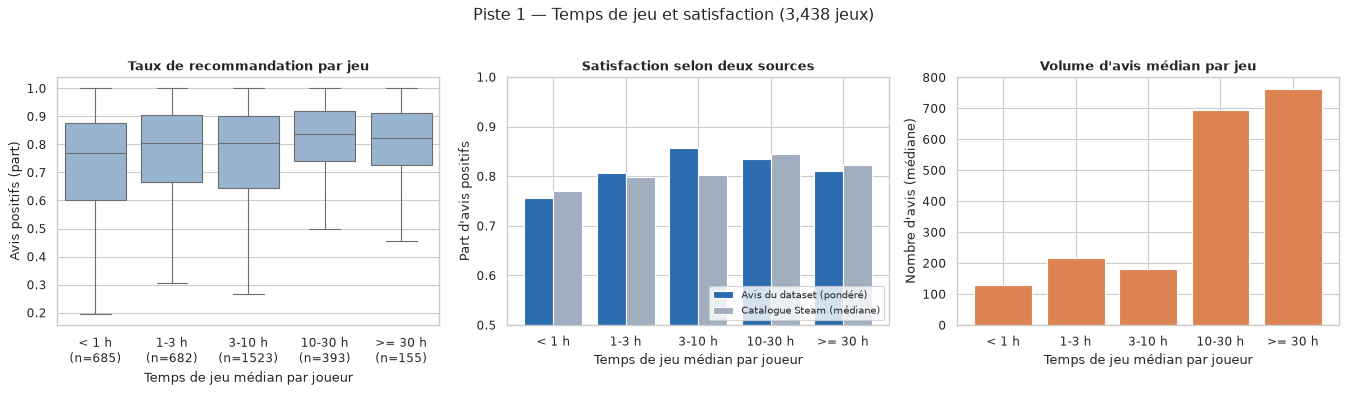

In [3]:
# (a) Valeurs manquantes déguisées : part de jeux à temps de jeu = 0 selon la tranche de propriétaires
zero_by_owners = (
    games_sdf.groupBy("owners_mid")
    .agg(
        F.count("*").alias("n_jeux"),
        F.avg((~F.col("playtime_measured")).cast("double")).alias("part_temps_0"),
        F.avg(F.when(~F.col("playtime_measured"), F.col("average_playtime"))).alias("average_si_med_0"),
    )
    .orderBy("owners_mid")
    .toPandas()
)
print("Temps de jeu = 0 selon la taille de la base de joueurs (tous les jeux avec avis) :")
print(zero_by_owners.to_string(index=False, float_format="{:.3f}".format))
rho_avg_med = stats.spearmanr(df_sample["average_playtime"], df_sample["median_playtime"])[0]
rho_pt_vol = stats.spearmanr(df_sample["median_playtime"], df_sample["n_reviews"])[0]
print(f"\nSpearman average_playtime ~ median_playtime = {rho_avg_med:.3f} (redondantes : médiane gardée)")
print(f"Spearman median_playtime ~ volume d'avis = {rho_pt_vol:.3f}")

# (b) Tranches de temps de jeu médian (en heures) et satisfaction
PLAYTIME_BINS = [0, 60, 180, 600, 1800, np.inf]  # minutes
PLAYTIME_LABELS = ["< 1 h", "1-3 h", "3-10 h", "10-30 h", ">= 30 h"]
df_sample["playtime_band"] = pd.cut(
    df_sample["median_playtime"], PLAYTIME_BINS, labels=PLAYTIME_LABELS, right=False
).astype(str)
df_sample["n_positive"] = df_sample["positive_ratio"] * df_sample["n_reviews"]
band_stats = (
    df_sample.groupby("playtime_band")
    .agg(
        n_jeux=("app_id", "size"),
        n_avis=("n_reviews", "sum"),
        n_pos=("n_positive", "sum"),
        reco_mediane_jeu=("positive_ratio", "median"),
        catalogue_mediane=("catalog_positive_ratio", "median"),
        avis_median=("n_reviews", "median"),
        utile_median=("helpful_ratio", "median"),
    )
    .reindex(PLAYTIME_LABELS)
)
band_stats["reco_ponderee_avis"] = band_stats["n_pos"] / band_stats["n_avis"]
band_stats = band_stats.drop(columns="n_pos")
print("\nSatisfaction par tranche de temps de jeu médian :")
print(band_stats.round(3).to_string())

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
sns.boxplot(
    data=df_sample, x="playtime_band", y="positive_ratio", order=PLAYTIME_LABELS, showfliers=False,
    color="#8fb3d9", ax=axes[0],
)
axes[0].set_xticks(range(len(PLAYTIME_LABELS)), [f"{b}\n(n={n})" for b, n in band_stats["n_jeux"].items()])
axes[0].set(title="Taux de recommandation par jeu", ylabel="Avis positifs (part)")

x = np.arange(len(PLAYTIME_LABELS))
for shift, col, label, color in [
    (-0.2, "reco_ponderee_avis", "Avis du dataset (pondéré)", "#2b6cb0"),
    (0.2, "catalogue_mediane", "Catalogue Steam (médiane)", "#a0aec0"),
]:
    axes[1].bar(x + shift, band_stats[col], 0.4, label=label, color=color)
axes[1].set_xticks(x, PLAYTIME_LABELS)
axes[1].set_ylim(0.5, 1)
axes[1].legend(loc="lower right", fontsize=9)
axes[1].set(title="Satisfaction selon deux sources", ylabel="Part d'avis positifs")

axes[2].bar(x, band_stats["avis_median"], color="#dd8452")
axes[2].set_xticks(x, PLAYTIME_LABELS)
axes[2].set(title="Volume d'avis médian par jeu", ylabel="Nombre d'avis (médiane)")
for ax in axes:
    ax.set_xlabel("Temps de jeu médian par joueur")
fig.suptitle(f"Piste 1 — Temps de jeu et satisfaction ({len(df_sample):,} jeux)", y=1.02)
plt.tight_layout()
plt.show()

**Lecture de la piste 1 :**
- **La satisfaction croît avec l'engagement jusqu'à 10-30 h.** Le taux de recommandation médian par jeu passe de 77,0 % (< 1 h) à 83,8 % (10-30 h), puis fléchit légèrement au-delà (82,2 %). Les jeux très chronophages (MMO, survie, bacs à sable) sont plus polarisants. La tendance est réelle mais la dispersion reste forte (boîtes larges), ce qui est cohérent avec le ρ faible du test #1.
- **La tranche < 1 h concentre les jeux « essayés puis abandonnés ».** Sa queue basse est la plus étendue : son premier quartile tombe à 60 % d'avis positifs, contre 72 à 74 % au-delà de 10 h.
- **Les deux sources de satisfaction concordent.** Les avis du dataset (pondérés) et le ratio du catalogue Steam suivent le même profil. Seule exception, la tranche 3-10 h (85,7 % contre 80,3 %) : la pondération par avis y est tirée par quelques gros titres très commentés.
- **Le temps de jeu entraîne la prise de parole.** Les jeux de 10-30 h et de plus de 30 h reçoivent 3 à 6 fois plus d'avis médians (695 et 763) que ceux de moins d'1 h (130). Un jeu auquel on joue longtemps crée une communauté qui s'exprime (ρ temps de jeu ~ volume = 0,25).

→ Le temps de jeu médian (en log) entre comme **feature d'engagement** dans le K-Means (§2).

### 1.3 Piste 2 — Vitalité du jeu : « toujours joué » ou « jeu mort » ?

Le catalogue ne contient aucun indicateur d'activité récente : ni joueurs simultanés, ni temps de jeu des deux dernières semaines. `median_playtime` est un temps de jeu **cumulé par joueur**. Nous construisons donc un indicateur de **rétention** qui croise trois dimensions : l'âge du jeu, son temps de jeu médian et sa base de propriétaires (`owners_mid`).

Le profil est défini par des **règles explicites**, et non par un modèle, pour rester interprétable et servir de grille de lecture indépendante des clusters :

| Profil | Règle (appliquée dans cet ordre) | Lecture |
|---|---|---|
| Niche confidentielle | `owners_mid` ≤ 35 000 (moins de 50 000 propriétaires) | audience trop faible pour parler de cycle de vie |
| Classique durable | âge ≥ 5 ans **et** temps médian ≥ seuil | ancien et toujours joué longtemps par chaque joueur |
| Hit récent | âge < 5 ans **et** temps médian ≥ seuil | récent et engageant |
| Vite abandonné / jeu mort | temps médian < seuil | les joueurs décrochent vite, quel que soit l'âge |

- **Âge** = année du snapshot du catalogue (2019) − année de sortie.
- **Seuil d'engagement** = médiane de l'échantillon (227 min ≈ 3,8 h) : une coupe neutre qui répartit les jeux en deux moitiés.

Seuils : niche <= 35,000 propriétaires | ancien >= 5 ans (sortie <= 2014) | engageant >= 227 min (3.8 h, médiane)

                           n_jeux  age_median  temps_median_h  proprietaires_median  reco_mediane_jeu  part_avis  reco_ponderee_avis
vitality_profile                                                                                                                    
Classique durable             790         6.0           6.792              350000.0             0.835      0.432               0.863
Hit récent                    740         3.0           6.400              350000.0             0.810      0.296               0.816
Vite abandonné / jeu mort    1404         5.0           1.550              350000.0             0.786      0.262               0.796
Niche confidentielle          504         4.0           2.942               35000.0             0.796      0.010               0.771

Kruskal-Wallis reco ~ profil de vitalité : H = 43.5, p = 1.92e-09


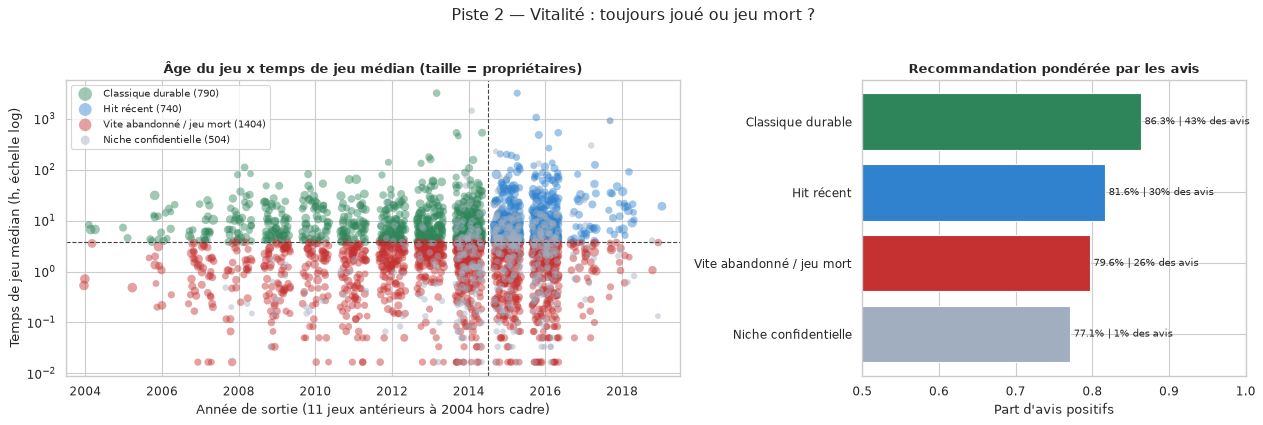

In [4]:
# Seuils du profil de vitalité (lisibles et reproductibles, cf. Markdown ci-dessus)
NICHE_MAX_OWNERS = 35_000  # 2 plus basses tranches SteamSpy (< 50 000 propriétaires)
OLD_MIN_AGE = 5  # sorti au moins 5 ans avant le snapshot du catalogue
ENGAGED_MIN_PLAYTIME = float(df_sample["median_playtime"].median())  # médiane de l'échantillon (minutes)
VITALITY_ORDER = ["Classique durable", "Hit récent", "Vite abandonné / jeu mort", "Niche confidentielle"]
VITALITY_COLORS = dict(zip(VITALITY_ORDER, ["#2f855a", "#3182ce", "#c53030", "#a0aec0"]))

engaged = df_sample["median_playtime"] >= ENGAGED_MIN_PLAYTIME
old = df_sample["game_age"] >= OLD_MIN_AGE
df_sample["vitality_profile"] = np.select(
    [df_sample["owners_mid"] <= NICHE_MAX_OWNERS, engaged & old, engaged & ~old],
    ["Niche confidentielle", "Classique durable", "Hit récent"],
    default="Vite abandonné / jeu mort",
)
assert set(df_sample["vitality_profile"]) <= set(VITALITY_ORDER)

vitality_stats = (
    df_sample.groupby("vitality_profile")
    .agg(
        n_jeux=("app_id", "size"),
        n_avis=("n_reviews", "sum"),
        n_pos=("n_positive", "sum"),
        age_median=("game_age", "median"),
        temps_median_h=("median_playtime", lambda s: s.median() / 60),
        proprietaires_median=("owners_mid", "median"),
        reco_mediane_jeu=("positive_ratio", "median"),
    )
    .reindex(VITALITY_ORDER)
)
vitality_stats["part_avis"] = vitality_stats["n_avis"] / vitality_stats["n_avis"].sum()
vitality_stats["reco_ponderee_avis"] = vitality_stats["n_pos"] / vitality_stats["n_avis"]
vitality_stats = vitality_stats.drop(columns=["n_avis", "n_pos"])
h_vit, p_vit = stats.kruskal(*[g["positive_ratio"] for _, g in df_sample.groupby("vitality_profile")])
print(
    f"Seuils : niche <= {NICHE_MAX_OWNERS:,} propriétaires | ancien >= {OLD_MIN_AGE} ans "
    f"(sortie <= {SNAPSHOT_YEAR - OLD_MIN_AGE}) | engageant >= {ENGAGED_MIN_PLAYTIME:.0f} min "
    f"({ENGAGED_MIN_PLAYTIME / 60:.1f} h, médiane)\n"
)
print(vitality_stats.round(3).to_string())
print(f"\nKruskal-Wallis reco ~ profil de vitalité : H = {h_vit:.1f}, p = {p_vit:.2e}")

rng = np.random.default_rng(42)  # jitter déterministe (années entières superposées)
fig, axes = plt.subplots(1, 2, figsize=(16, 5.2), gridspec_kw={"width_ratios": [1.6, 1]})
for profile in VITALITY_ORDER:
    sub = df_sample[df_sample["vitality_profile"] == profile]
    axes[0].scatter(
        sub["release_year"] + rng.uniform(-0.35, 0.35, len(sub)), sub["median_playtime"] / 60,
        s=6 + 4 * np.log10(sub["owners_mid"]) ** 2 / 3, alpha=0.45, color=VITALITY_COLORS[profile],
        label=f"{profile} ({len(sub)})", edgecolors="none",
    )
axes[0].axhline(ENGAGED_MIN_PLAYTIME / 60, ls="--", color="#444", lw=1)
axes[0].axvline(SNAPSHOT_YEAR - OLD_MIN_AGE + 0.5, ls="--", color="#444", lw=1)
axes[0].set_yscale("log")
X_MIN_YEAR = 2004  # les quelques jeux plus anciens sont hors cadre (lisibilité)
n_older = int((df_sample["release_year"] < X_MIN_YEAR).sum())
axes[0].set_xlim(X_MIN_YEAR - 0.5, SNAPSHOT_YEAR + 0.5)
axes[0].legend(fontsize=9, loc="upper left", markerscale=1.5)
axes[0].set(
    title="Âge du jeu x temps de jeu médian (taille = propriétaires)",
    xlabel=f"Année de sortie ({n_older} jeux antérieurs à {X_MIN_YEAR} hors cadre)",
    ylabel="Temps de jeu médian (h, échelle log)",
)

bars = axes[1].barh(
    VITALITY_ORDER[::-1], vitality_stats.loc[VITALITY_ORDER[::-1], "reco_ponderee_avis"],
    color=[VITALITY_COLORS[p] for p in VITALITY_ORDER[::-1]],
)
for bar, (_, row) in zip(bars, vitality_stats.loc[VITALITY_ORDER[::-1]].iterrows()):
    axes[1].text(
        bar.get_width() + 0.005, bar.get_y() + bar.get_height() / 2,
        f"{row['reco_ponderee_avis']:.1%} | {row['part_avis']:.0%} des avis", va="center", fontsize=9,
    )
axes[1].set_xlim(0.5, 1.0)
axes[1].set(title="Recommandation pondérée par les avis", xlabel="Part d'avis positifs")
fig.suptitle("Piste 2 — Vitalité : toujours joué ou jeu mort ?", y=1.02)
plt.tight_layout()
plt.show()

**Lecture de la piste 2 :**
- **Répartition.** 790 classiques durables, 740 hits récents, 1 404 jeux vite abandonnés et 504 niches confidentielles.
- **Les classiques durables dominent.** Ils portent 43 % des avis et ont la meilleure recommandation (86,3 % pondéré). C'est en partie un **effet survivant** : seuls les bons jeux sont encore joués longtemps 5 ans après leur sortie.
- **La hiérarchie suit la rétention.** Hits récents 81,6 %, jeux vite abandonnés 79,6 %, niches 77,1 % (1 % des avis seulement). Les profils diffèrent significativement (Kruskal-Wallis H = 43,5, p = 1,9·10⁻⁹), mais l'écart reste modeste.
- **Limites assumées :**
  - « jeu mort » signifie ici une faible rétention cumulée, pas l'absence de joueurs aujourd'hui ;
  - le dataset d'avis couvre très mal les sorties 2017-2019 (artefact de collecte relevé au Jour 3) : les « hits récents » sont surtout des jeux de 2015-2016.

→ Ce profil sert à **caractériser** les segments K-Means (§2). L'âge, lui, entre directement dans les features.

### 1.4 Note méthodologique — Le texte des avis, une limite assumée

- **Choix.** Le dataset source `andrewmvd/steam-reviews` contient le texte de chaque avis (`review_text`). Nous l'avons **volontairement écarté dès l'ingestion (Jour 1)** pour respecter le dimensionnement du projet :
  - avec le texte, le fichier dépasse largement le gabarit du TP (50-500 Mo) ;
  - sans le texte et après échantillonnage, il pèse environ **100 Mo** (3,76 M avis).

  Exploiter le texte demanderait aussi une chaîne NLP complète (nettoyage, tokenisation, TF-IDF ou embeddings, modèle de sentiment), hors du périmètre du TP.
- **Conséquence.** Nous ne pouvons pas analyser les *motifs* de satisfaction (bugs, prix, contenu, optimisation) ni nuancer le sentiment au-delà du binaire recommandé / non recommandé.
- **Compensation par deux signaux comportementaux**, présents sur chaque avis :
  - `is_helpful` (issu de `review_votes`) : l'avis a été jugé utile par au moins un joueur. C'est un signal d'**engagement de la communauté** : le test #3 montre qu'un avis négatif est 1,9 fois plus souvent jugé utile.
  - `is_contrarian_review` (construit au Jour 2) : l'avis contredit le consensus du jeu dans le catalogue Steam. C'est un signal de **polarisation**.

  Agrégés par jeu (`helpful_ratio`, `contrarian_ratio`), ces deux signaux **caractérisent les segments** du §2. Ils restent hors des features du K-Means, pour conserver 5 variables peu redondantes.
- **Perspective.** Avec davantage de stockage, on ajouterait le texte en Bronze, puis on extrairait les thèmes (TF-IDF + LDA) ou un sentiment fin avec Spark ML.

## 2. Segmentation / Typologie par Clustering K-Means (`/lakehouse/gold/`)

Quelle que soit la thématique de votre dataset Kaggle, identifiez l'**entité métier pertinente à segmenter** (ex. clients/utilisateurs, stations, zones géographiques, produits, lignes de transport, capteurs...) :
1. **Agrégation PySpark** : résumez chaque entité par **3 à 5 features numériques comportementales** (fréquence, volume, valeur médiane/totale, récence, taux d'incident...).
2. **Prétraitement statistique** : appliquez `np.log1p(...)` sur les features positives asymétriques puis centrez-réduisez avec `StandardScaler()` afin qu'aucune variable à grande échelle n'écrase la distance euclidienne du K-Means.
3. **Interprétation métier** : inspectez les médianes par cluster (`groupby("cluster_id").median()`), attribuez un **nom explicite** à chaque segment (`colonne "segment"`), puis enregistrez la table dans **`/lakehouse/gold/<nom_table_segments>`**.

### Choix de l'entité, des features et du prétraitement

- **Entité = jeu (`app_id`).** C'est l'échelle où se prennent les décisions (prix, mise en avant, suivi du catalogue). Nous reprenons le périmètre des tests : 3 438 jeux.
- **5 features comportementales**, calculées côté PySpark :

| Feature | Dimension | Transformation (skewness avant → après) |
|---|---|---|
| `n_reviews` | volume / popularité | `log1p` (9,29 → 0,57) |
| `positive_ratio` | satisfaction | aucune : variable bornée dans [0, 1], asymétrie à gauche modérée (−1,09) que `log1p` ne corrigerait pas |
| `median_playtime` | engagement (piste 1) | `log1p` (29,07 → −0,48) |
| `price` | positionnement prix | `log1p` (1,92 → −0,49), qui gère les jeux gratuits (log1p(0) = 0) |
| `game_age` | cycle de vie (piste 2) | `log1p` (1,46 → 0,20) |

- **Variables écartées :**
  - `owners_mid`, très corrélée au volume d'avis (ρ = 0,73) et réduite à 12 tranches discrètes ;
  - `average_playtime`, redondante avec la médiane (ρ = 0,92) ;
  - `helpful_ratio` et `contrarian_ratio`, gardés pour l'interprétation (piste 3).
- **Pipeline Spark ML :** `VectorAssembler` → `StandardScaler(withMean=True, withStd=True)` → `KMeans`. Le centrage-réduction est indispensable : K-Means repose sur la distance euclidienne, et sans lui `log_n_reviews` (de 3 à 11) écraserait `positive_ratio` (de 0 à 1).
- **Choix de k (2 à 8)** à l'aide de deux critères :
  - l'**inertie** intra-cluster, lue avec la méthode du coude ;
  - le **score de silhouette**, entre −1 et 1, qui compare la cohésion interne des clusters à leur séparation.

Asymétrie des features (|skew| > 1 = forte asymétrie) :
                 skew_brute  skew_modele       feature_modele
feature                                                      
n_reviews              9.29         0.57        log_n_reviews
positive_ratio        -1.09        -1.09       positive_ratio
median_playtime       29.07        -0.48  log_median_playtime
price                  1.92        -0.49            log_price
game_age               1.46         0.20         log_game_age

Spearman owners_mid ~ n_reviews = 0.73 -> owners_mid exclu des features (redondant)


netlib-blas: JNI_OnLoad: dlopen(libblas.so.3) failed: libblas.so.3: cannot open shared object file: No such file or directory



Sélection du nombre de clusters :
      inertie  silhouette  gain_inertie
k                                      
2  13257.4584      0.3437           NaN
3  11620.0234      0.3008     1637.4349
4  10118.3314      0.3056     1501.6921
5   8767.4827      0.3461     1350.8487
6   7971.0004      0.3490      796.4822
7   7602.2594      0.3114      368.7410
8   7094.3198      0.3198      507.9397

-> k retenu = 5 (silhouette 0.346)


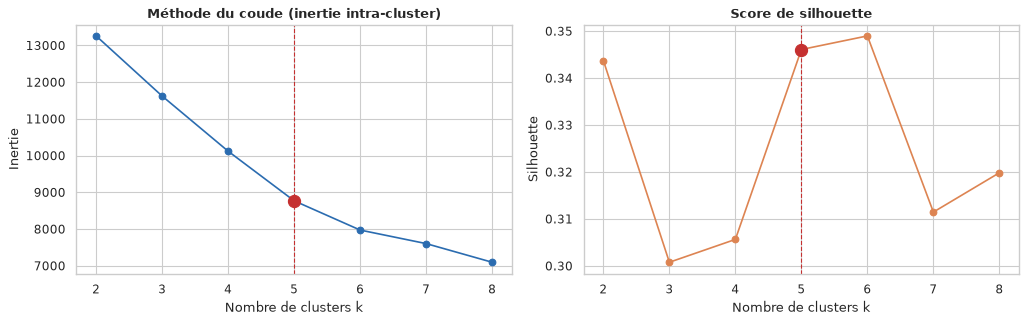

In [5]:
# Entité = jeu. 5 features comportementales (volume, satisfaction, engagement, prix, cycle de vie)
RAW_FEATURES = ["n_reviews", "positive_ratio", "median_playtime", "price", "game_age"]
LOG_FEATURES = ["n_reviews", "median_playtime", "price", "game_age"]  # positives, asymétriques à droite
MODEL_FEATURES = [f"log_{c}" if c in LOG_FEATURES else c for c in RAW_FEATURES]

# Préparation 100 % PySpark : même filtre que l'échantillon des tests, log1p calculé côté Spark.
# Table de quelques milliers de lignes -> 1 partition triée : K-Means reproductible à graine fixe.
entities_sdf = games_sdf.filter((F.col("n_reviews") >= MIN_REVIEWS) & F.col("playtime_measured")).select(
    "app_id", *RAW_FEATURES, *[F.log1p(c).alias(f"log_{c}") for c in LOG_FEATURES]
)
entities_sdf = entities_sdf.orderBy("app_id").coalesce(1).cache()
assert entities_sdf.count() == len(df_sample)

# Justification du log1p : asymétrie (skewness) avant / après transformation
skew_cols = RAW_FEATURES + [f"log_{c}" for c in LOG_FEATURES]
skew_row = entities_sdf.select(*[F.skewness(c).alias(c) for c in skew_cols]).first()
skew_table = pd.DataFrame(
    {
        "skew_brute": [skew_row[c] for c in RAW_FEATURES],
        "skew_modele": [skew_row[m] for m in MODEL_FEATURES],
    },
    index=pd.Index(RAW_FEATURES, name="feature"),
).assign(feature_modele=MODEL_FEATURES)
print("Asymétrie des features (|skew| > 1 = forte asymétrie) :")
print(skew_table.round(2).to_string())
assert (skew_table["skew_modele"].abs() < 1.2).all(), "Une feature du modèle reste très asymétrique"

rho_owners = stats.spearmanr(df_sample["owners_mid"], df_sample["n_reviews"])[0]
print(f"\nSpearman owners_mid ~ n_reviews = {rho_owners:.2f} -> owners_mid exclu des features (redondant)")

# Pipeline Spark ML : VectorAssembler -> StandardScaler (centrage-réduction : z-scores)
assembler = VectorAssembler(inputCols=MODEL_FEATURES, outputCol="features_raw")
scaler = SparkStandardScaler(inputCol="features_raw", outputCol="features", withMean=True, withStd=True)
features_sdf = Pipeline(stages=[assembler, scaler]).fit(entities_sdf).transform(entities_sdf).cache()

# Choix de k : inertie intra-cluster (méthode du coude) + score de silhouette, k = 2..8
evaluator = ClusteringEvaluator(
    featuresCol="features",
    predictionCol="cluster_id",
    metricName="silhouette",
    distanceMeasure="squaredEuclidean",
)
k_rows = []
for k in range(2, 9):
    km = SparkKMeans(k=k, seed=42, maxIter=50, featuresCol="features", predictionCol="cluster_id")
    km = km.fit(features_sdf)
    k_rows.append((k, km.summary.trainingCost, evaluator.evaluate(km.transform(features_sdf))))
k_scores = pd.DataFrame(k_rows, columns=["k", "inertie", "silhouette"]).set_index("k")
k_scores["gain_inertie"] = -k_scores["inertie"].diff()
print("\nSélection du nombre de clusters :")
print(k_scores.round(4).to_string())

K_FINAL = 5  # coude (le gain d'inertie chute de moitié après k=5) + silhouette quasi maximale
assert k_scores.loc[K_FINAL, "silhouette"] >= 0.97 * k_scores["silhouette"].max()
assert k_scores.loc[K_FINAL + 1, "gain_inertie"] < 0.7 * k_scores.loc[K_FINAL, "gain_inertie"]
print(f"\n-> k retenu = {K_FINAL} (silhouette {k_scores.loc[K_FINAL, 'silhouette']:.3f})")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].plot(k_scores.index, k_scores["inertie"], marker="o", color="#2b6cb0")
axes[1].plot(k_scores.index, k_scores["silhouette"], marker="o", color="#dd8452")
for ax, col, title in [
    (axes[0], "inertie", "Méthode du coude (inertie intra-cluster)"),
    (axes[1], "silhouette", "Score de silhouette"),
]:
    ax.axvline(K_FINAL, ls="--", color="#c53030", lw=1)
    ax.scatter([K_FINAL], [k_scores.loc[K_FINAL, col]], s=120, color="#c53030", zorder=3)
    ax.set(title=title, xlabel="Nombre de clusters k", ylabel=col.capitalize())
plt.tight_layout()
plt.show()

In [6]:
GOLD_SEGMENTS_PATH = "/lakehouse/gold/game_segments"

# Étape 1 : entités agrégées côté PySpark (`entities_sdf`, cellule précédente). Pipeline Spark ML complet
# (assemblage -> centrage-réduction -> K-Means), puis seuls (app_id, cluster_id) remontent au driver pour
# être joints au profil jeu déjà rapatrié (`df_sample`, ~3 400 lignes).
seg_model = Pipeline(
    stages=[
        assembler,
        scaler,
        SparkKMeans(k=K_FINAL, seed=42, maxIter=50, featuresCol="features", predictionCol="cluster_id"),
    ]
).fit(entities_sdf)
labels_pd = seg_model.transform(entities_sdf).select("app_id", "cluster_id").toPandas()
entities_pd = df_sample.drop(columns="n_positive").merge(labels_pd, on="app_id", validate="1:1")
assert entities_pd is not None, "TODO : Construisez le DataFrame d'entités agrégées `entities_pd`."
assert len(entities_pd) == len(df_sample)

# Étape 2 : nommage métier à partir des centroïdes (z-scores). Attribution par règles successives sur le
# trait dominant de chaque cluster -> noms indépendants de la numérotation arbitraire des clusters.
centers = pd.DataFrame(seg_model.stages[-1].clusterCenters(), columns=MODEL_FEATURES)
NAMING_RULES = [  # (segment, feature du centroïde, extrême recherché)
    ("Jeux décevants & controversés", "positive_ratio", "min"),
    ("Free-to-play à faible rétention", "log_price", "min"),
    ("Anciens classiques du catalogue", "log_game_age", "max"),
    ("Hits premium à forte rétention", "log_n_reviews", "max"),
]
assert len(NAMING_RULES) == K_FINAL - 1, "Règles de nommage à revoir si k change"
remaining, segment_names = list(centers.index), {}
for label, col, how in NAMING_RULES:
    cid = getattr(centers.loc[remaining, col], f"idx{how}")()
    segment_names[cid] = label
    remaining.remove(cid)
segment_names[remaining[0]] = "Pépites de niche appréciées"
entities_pd["segment"] = entities_pd["cluster_id"].map(segment_names)

# Garde-fous : le nom de chaque segment doit rester vrai sur les médianes observées
med = entities_pd.groupby("segment")[RAW_FEATURES].median()
assert med["positive_ratio"].idxmin() == "Jeux décevants & controversés"
assert med.loc["Free-to-play à faible rétention", "price"] < 1
assert med["game_age"].idxmax() == "Anciens classiques du catalogue"
assert med["n_reviews"].idxmax() == "Hits premium à forte rétention"
assert med.loc["Pépites de niche appréciées", "positive_ratio"] > entities_pd["positive_ratio"].median()

# Robustesse : K-Means scikit-learn (20 initialisations) sur les mêmes features -> accord avec Spark ML
X_model = np.column_stack(
    [np.log1p(entities_pd[c]) if c in LOG_FEATURES else entities_pd[c] for c in RAW_FEATURES]
)
X_std = StandardScaler().fit_transform(X_model)
sk_labels = KMeans(n_clusters=K_FINAL, n_init=20, random_state=42).fit_predict(X_std)
ari = adjusted_rand_score(entities_pd["cluster_id"], sk_labels)
print(f"Accord Spark ML vs scikit-learn (Adjusted Rand Index) : {ari:.3f}")
assert ari > 0.8, "Segmentation instable selon l'implémentation / l'initialisation"
print(entities_pd["segment"].value_counts().to_string())

assert "segment" in entities_pd.columns, "TODO : Ajoutez une colonne lisible `segment` décrivant chaque cluster."

# Étape 3 : Sauvegarder en Delta Lake sur HDFS dans `GOLD_SEGMENTS_PATH`
(
    spark.createDataFrame(entities_pd)
    .coalesce(2)
    .write.format("delta")
    .mode("overwrite")
    .option("overwriteSchema", "true")
    .save(GOLD_SEGMENTS_PATH)
)
print(f"Table de segmentation enregistrée dans {GOLD_SEGMENTS_PATH} ({len(entities_pd):,} entités) !")

Accord Spark ML vs scikit-learn (Adjusted Rand Index) : 0.983
segment
Pépites de niche appréciées        993
Hits premium à forte rétention     735
Anciens classiques du catalogue    686
Jeux décevants & controversés      568
Free-to-play à faible rétention    456


Table de segmentation enregistrée dans /lakehouse/gold/game_segments (3,438 entités) !


                                 n_jeux  avis_median  reco_mediane  temps_median_h  prix_median  age_median  proprietaires_median  utile_median  contrarien_median  part_avis  reco_ponderee
segment                                                                                                                                                                                     
Hits premium à forte rétention      735       1395.0         0.863           9.167        14.99         5.0              750000.0         0.134              0.137      0.669          0.851
Anciens classiques du catalogue     686        270.5         0.836           2.467         6.99         9.0              350000.0         0.115              0.164      0.102          0.862
Pépites de niche appréciées         993         91.0         0.844           3.950         6.99         4.0               75000.0         0.225              0.156      0.038          0.845
Free-to-play à faible rétention     456        379.5   

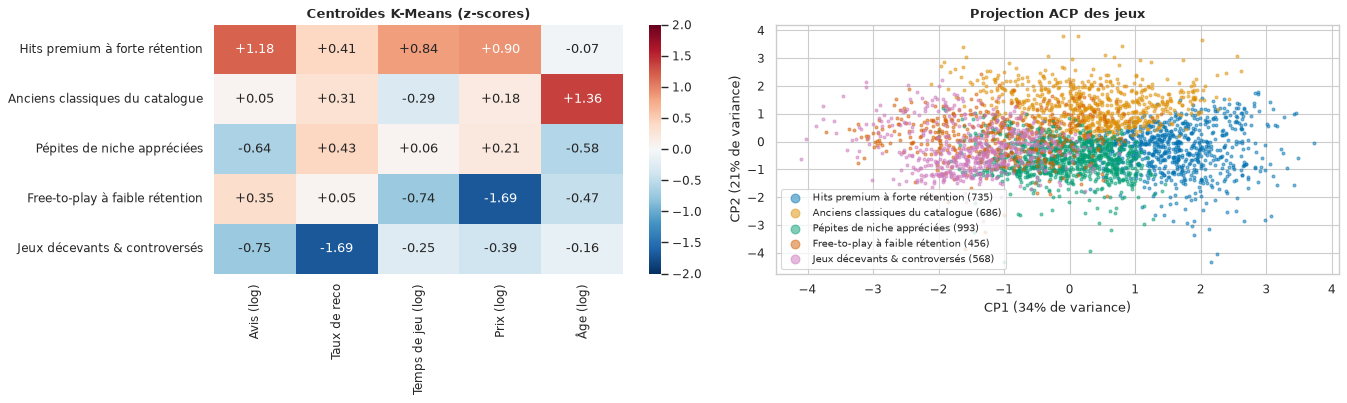

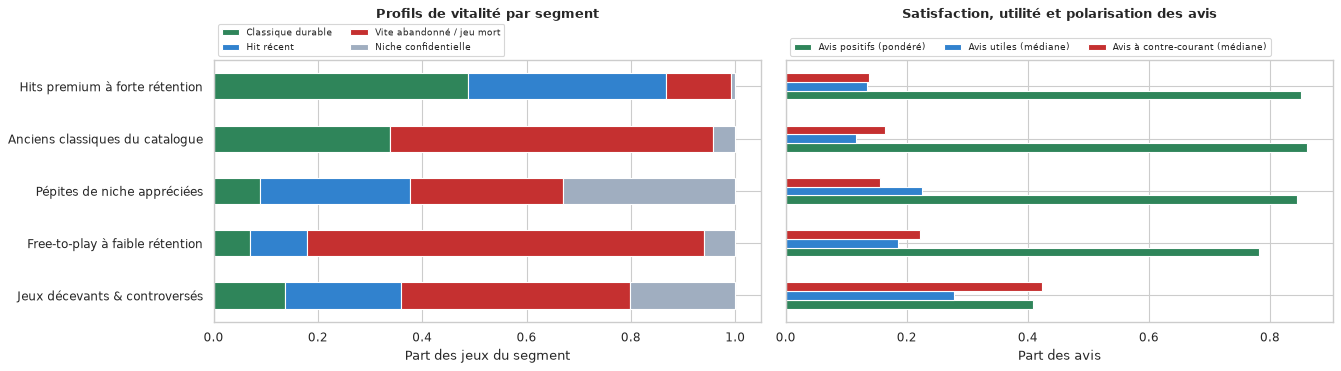

In [7]:
SEGMENT_ORDER = [
    "Hits premium à forte rétention",
    "Anciens classiques du catalogue",
    "Pépites de niche appréciées",
    "Free-to-play à faible rétention",
    "Jeux décevants & controversés",
]
SEGMENT_COLORS = dict(zip(SEGMENT_ORDER, sns.color_palette("colorblind", K_FINAL)))
entities_pd["n_positive"] = entities_pd["positive_ratio"] * entities_pd["n_reviews"]

# Profil médian par segment (indicateurs robustes : distributions asymétriques) + signaux de la piste 3
profile = (
    entities_pd.groupby("segment")
    .agg(
        n_jeux=("app_id", "size"),
        n_avis=("n_reviews", "sum"),
        n_pos=("n_positive", "sum"),
        avis_median=("n_reviews", "median"),
        reco_mediane=("positive_ratio", "median"),
        temps_median_h=("median_playtime", lambda s: s.median() / 60),
        prix_median=("price", "median"),
        age_median=("game_age", "median"),
        proprietaires_median=("owners_mid", "median"),
        utile_median=("helpful_ratio", "median"),
        contrarien_median=("contrarian_ratio", "median"),
    )
    .reindex(SEGMENT_ORDER)
)
profile["part_avis"] = profile["n_avis"] / profile["n_avis"].sum()
profile["reco_ponderee"] = profile["n_pos"] / profile["n_avis"]
profile = profile.drop(columns=["n_avis", "n_pos"])
entities_pd = entities_pd.drop(columns="n_positive")
with pd.option_context("display.width", 200):
    print(profile.round(3).to_string())

vitality_mix = pd.crosstab(entities_pd["segment"], entities_pd["vitality_profile"], normalize="index")
vitality_mix = vitality_mix.reindex(index=SEGMENT_ORDER, columns=VITALITY_ORDER, fill_value=0)
print("\nComposition des segments par profil de vitalité (piste 2) :")
print(vitality_mix.round(3).to_string())
genre_top = (
    entities_pd.groupby("segment")["primary_genre"]
    .agg(lambda s: ", ".join(f"{g} {v:.0%}" for g, v in s.value_counts(normalize=True).head(3).items()))
    .reindex(SEGMENT_ORDER)
)
examples = (
    entities_pd.sort_values("n_reviews", ascending=False)
    .groupby("segment")["game_name"]
    .agg(lambda s: " | ".join(s.head(3)))
    .reindex(SEGMENT_ORDER)
)
print("\nGenres dominants et jeux les plus commentés par segment :")
for seg in SEGMENT_ORDER:
    print(f" - {seg:<33} : {genre_top[seg]}  ->  {examples[seg]}")

# Figure 1 : centroïdes standardisés (heatmap) + projection ACP 2D
centers_named = centers.rename(index=segment_names).reindex(SEGMENT_ORDER)
centers_named.columns = ["Avis (log)", "Taux de reco", "Temps de jeu (log)", "Prix (log)", "Âge (log)"]
pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(X_std)
fig, axes = plt.subplots(1, 2, figsize=(17, 5.2), gridspec_kw={"width_ratios": [1, 1.1]})
sns.heatmap(centers_named, annot=True, fmt="+.2f", cmap="RdBu_r", center=0, vmin=-2, vmax=2, ax=axes[0])
axes[0].set(title="Centroïdes K-Means (z-scores)", xlabel="", ylabel="")
for seg in SEGMENT_ORDER:
    mask = (entities_pd["segment"] == seg).to_numpy()
    axes[1].scatter(
        coords[mask, 0],
        coords[mask, 1],
        s=7,
        alpha=0.5,
        color=SEGMENT_COLORS[seg],
        label=f"{seg} ({mask.sum()})",
    )
axes[1].legend(fontsize=9, markerscale=3, loc="best")
axes[1].set(
    title="Projection ACP des jeux",
    xlabel=f"CP1 ({pca.explained_variance_ratio_[0]:.0%} de variance)",
    ylabel=f"CP2 ({pca.explained_variance_ratio_[1]:.0%} de variance)",
)
plt.tight_layout()
plt.show()

# Figure 2 : vitalité (piste 2) et signaux d'engagement / polarisation (piste 3) par segment
fig, axes = plt.subplots(1, 2, figsize=(17, 4.8))
vitality_colors = [VITALITY_COLORS[v] for v in VITALITY_ORDER]
vitality_mix.iloc[::-1].plot.barh(stacked=True, color=vitality_colors, ax=axes[0])
axes[0].legend(fontsize=8, loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2)
axes[0].set(xlabel="Part des jeux du segment", ylabel="")
axes[0].set_title("Profils de vitalité par segment", pad=38)
signals = profile[["reco_ponderee", "utile_median", "contrarien_median"]].iloc[::-1]
signals.columns = ["Avis positifs (pondéré)", "Avis utiles (médiane)", "Avis à contre-courant (médiane)"]
signals.plot.barh(ax=axes[1], color=["#2f855a", "#3182ce", "#c53030"])
axes[1].legend(fontsize=8, loc="lower left", bbox_to_anchor=(0, 1.0), ncol=3)
axes[1].set(xlabel="Part des avis", ylabel="")
axes[1].set_title("Satisfaction, utilité et polarisation des avis", pad=38)
axes[1].tick_params(labelleft=False)
plt.tight_layout()
plt.show()

### Interprétation métier des 5 segments

**Pourquoi k = 5 ?**
- **Coude.** Le gain d'inertie passe de 1 351 (k = 4 → 5) à 796 (k = 5 → 6) : chaque cluster supplémentaire au-delà de 5 apporte deux fois moins.
- **Silhouette.** Elle vaut 0,346 à k = 5, quasi égale au maximum (0,349 à k = 6). Le k = 2 (0,344) ne sépare que les « gros » des « petits » jeux, sans valeur métier.
- **Structure modérée.** Une silhouette d'environ 0,35 indique que les segments découpent utilement un continuum, plutôt que des groupes isolés. L'ACP le confirme : les nuages se chevauchent, et les deux premiers axes portent 55 % de la variance.
- **Robustesse.** Un K-Means scikit-learn (20 initialisations) retrouve la même partition que Spark ML (**ARI = 0,983**). La segmentation ne dépend donc ni de l'implémentation ni de l'initialisation.

| Segment | Jeux | Part des avis | Reco. pondérée | Temps médian | Prix médian | Âge médian | Vitalité dominante | Exemples |
|---|---|---|---|---|---|---|---|---|
| **Hits premium à forte rétention** | 735 | **66,9 %** | 85,1 % | 9,2 h | 14,99 £ | 5 ans | classique durable 49 % + hit récent 38 % | DayZ, PAYDAY 2, Terraria |
| **Anciens classiques du catalogue** | 686 | 10,2 % | **86,2 %** | 2,5 h | 6,99 £ | **9 ans** | vite abandonné 62 % | Counter-Strike: Source, Portal |
| **Pépites de niche appréciées** | 993 | 3,8 % | 84,5 % | 4,0 h | 6,99 £ | 4 ans | niche 33 %, hit récent 29 % | Melody's Escape, Crawl |
| **Free-to-play à faible rétention** | 456 | 17,1 % | 78,2 % | **1,1 h** | **0 £** | 4 ans | vite abandonné **76 %** | Warframe, Robocraft |
| **Jeux décevants & controversés** | 568 | 2,1 % | **40,8 %** | 3,5 h | 3,99 £ | 4 ans | vite abandonné 44 % | Spacebase DF-9, Takedown: Red Sabre |

1. **Hits premium à forte rétention : le cœur du marché.**
   - Ce sont 21 % des jeux, mais deux tiers des avis.
   - Leur base de joueurs est large (750 000 propriétaires médians) et l'engagement élevé (9 h médianes) justifie un prix plein.
   - **Action :** suites, contenus additionnels, prix premium.
2. **Anciens classiques du catalogue : reconnus, mais leur base de joueurs s'est diluée.**
   - Ils ont la meilleure note, mais 62 % présentent une faible rétention.
   - Soldes, bundles et gratuités ponctuelles leur ont apporté beaucoup de propriétaires qui jouent peu.
   - **Action :** remasters et soldes de fond de catalogue.
3. **Pépites de niche appréciées : petites communautés très satisfaites.**
   - 91 avis médians et 75 000 propriétaires, pour 84,5 % de recommandation.
   - Leurs avis sont plus souvent jugés utiles (22,5 %) : les acheteurs potentiels lisent attentivement ces avis.
   - **Action :** visibilité (mise en avant, moteur de recommandation).
4. **Free-to-play à faible rétention : le gratuit attire du volume, pas de la fidélité.**
   - 1,1 h de jeu médian, 76 % de jeux vite abandonnés et 22 % d'avis à contre-courant.
   - **Action :** l'enjeu est la rétention (prise en main, premières heures de jeu), pas l'acquisition.
5. **Jeux décevants & controversés : signal d'alerte qualité.**
   - Seulement 40,8 % d'avis positifs, une polarisation maximale (42 % d'avis à contre-courant) et l'utilité la plus élevée (28 %).
   - Les critiques y sont lues et approuvées. Spacebase DF-9 en est l'exemple type : un développement abandonné en accès anticipé.

**Cohérence avec les tests du §1 :**
- La hiérarchie des prix du test #2 se retrouve dans les segments : free-to-play 78 % contre premium 85 %.
- Le test #3 aussi : les segments les moins bien notés ont les avis les plus souvent jugés utiles.

La table Gold `/lakehouse/gold/game_segments` (1 ligne par jeu : `segment`, `cluster_id`, `vitality_profile`, `playtime_band`, métriques brutes) alimentera les filtres du dashboard.

## 3. Livrable Final : Votre Application `app/dashboard.py` sur Streamlit (`:8501`)

Complétez maintenant **`app/dashboard.py`** pour valoriser vos tables `/lakehouse/gold/` :
- **Architecture respectée** : l'application Streamlit ne doit lire **que** des tables pré-calculées de la couche **Gold** (`/lakehouse/gold/...`), jamais les fichiers CSV bruts !
- **Interactivité** : au moins un filtre utilisateur (`st.selectbox`, `st.multiselect`, `st.slider`) et 3 à 4 visualisations Plotly Express complémentaires.
- **Rigueur explicative** : sous chaque visualisation clé, intégrez un `st.expander("Requête SQL & Justification statistique")` affichant la requête Spark SQL ayant produit la table Gold et justifiant le choix des indicateurs statistiques retenus.

In [8]:
# Vérification finale de l'inventaire complet de votre couche Gold sur HDFS
jvm = spark._jvm
fs = jvm.org.apache.hadoop.fs.FileSystem.get(spark._jsc.hadoopConfiguration())
PathHDFS = jvm.org.apache.hadoop.fs.Path
gold_root = PathHDFS("/lakehouse/gold")

gold_tables = [
    s.getPath().getName()
    for s in fs.listStatus(gold_root)
    if s.isDirectory() and fs.exists(PathHDFS(s.getPath(), "_delta_log"))
]
assert len(gold_tables) > 0, "Aucune table Delta trouvée dans /lakehouse/gold/ !"

print("=== Tables Delta disponibles dans /lakehouse/gold/ pour Streamlit ===")
for t in sorted(gold_tables):
    cnt = spark.read.format("delta").load(f"/lakehouse/gold/{t}").count()
    print(f" - /lakehouse/gold/{t:<25} : {cnt:>9,} lignes")

=== Tables Delta disponibles dans /lakehouse/gold/ pour Streamlit ===


 - /lakehouse/gold/game_segments             :     3,438 lignes


 - /lakehouse/gold/genre_pareto              :        20 lignes


 - /lakehouse/gold/release_year_trends       :        23 lignes


 - /lakehouse/gold/top_games_by_genre        :       133 lignes
